# Hypothesis: In summer the bakery sells more croissants

**Purpose.** We test whether croissant revenue (product group 3) is higher in summer than in the rest of the year. This shows how strong the seasonal difference is and whether our prediction needs a seasonal signal.

**Definitions** (decision log, 2026-11-23):
- Summer = meteorological summer, 1 June – 31 August. Comparison: summer days against all other days (September – May).
- The data contains revenue (`Umsatz`), not units, so "sells more" means "has higher revenue".
- "More" = the average daily revenue is higher in summer and the 95 % confidence interval of the difference lies entirely above zero. We also report the size of the difference.
- Only the training period (2013-07-01 – 2017-07-31) is used, without 2014-05-05 (one-off peak). The validation year is not touched.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/umsatzdaten_gekuerzt.csv"
sales = pd.read_csv(URL, parse_dates=["Datum"])

TRAIN_END = "2017-07-31"
train = sales[(sales["Datum"] <= TRAIN_END) & (sales["Datum"] != "2014-05-05")].copy()
train["summer"] = train["Datum"].dt.month.isin([6, 7, 8])
train["month"] = train["Datum"].dt.month
train["year"] = train["Datum"].dt.year
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
train["weekday"] = pd.Categorical(train["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)

croissants = train[train["Warengruppe"] == 3]
print(f"Croissant rows in training: {len(croissants)}; summer days: {croissants['summer'].sum()}, other days: {(~croissants['summer']).sum()}")

Croissant rows in training: 1461; summer days: 393, other days: 1068


## 1. Average revenue per month

First look: the average daily croissant revenue per month with a 95 % confidence interval (the range in which the true average most likely lies). We check whether summer differs from spring and autumn, or only from winter.

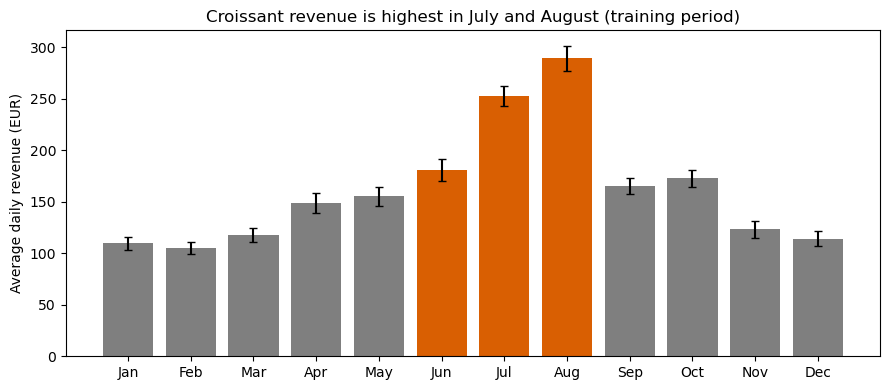

,n,mean,ci_low,ci_high
month,,,,
1,120.0,109.6,103.0,116.1
2,113.0,105.3,99.4,111.2
3,122.0,117.8,111.2,124.5
4,117.0,149.0,139.1,158.8
5,118.0,155.5,146.1,164.9
6,120.0,180.6,170.0,191.3
7,152.0,252.7,243.1,262.3
8,121.0,289.5,277.6,301.5
9,120.0,165.3,157.2,173.3


In [2]:
def mean_ci(x):
    x = np.asarray(x, dtype=float)
    m = x.mean()
    h = stats.sem(x) * stats.t.ppf(0.975, len(x) - 1)
    return pd.Series({"n": len(x), "mean": m, "ci_low": m - h, "ci_high": m + h})

monthly = croissants.groupby("month")["Umsatz"].apply(mean_ci).unstack()
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#d95f02" if m in (6, 7, 8) else "#7f7f7f" for m in monthly.index]
ax.bar(monthly.index, monthly["mean"], color=colors,
       yerr=[monthly["mean"] - monthly["ci_low"], monthly["ci_high"] - monthly["mean"]], capsize=3)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_ylabel("Average daily revenue (EUR)")
ax.set_title("Croissant revenue is highest in July and August (training period)")
plt.tight_layout(); plt.show()
monthly.round(1)

## 2. Summer against all other days

Test of the hypothesis as defined: difference of the average daily revenue (summer minus other days) with a 95 % confidence interval (Welch t-test, which does not assume equal spread in both groups).

In [3]:
s = croissants.loc[croissants["summer"], "Umsatz"]
o = croissants.loc[~croissants["summer"], "Umsatz"]
diff = s.mean() - o.mean()
se = np.sqrt(s.var(ddof=1)/len(s) + o.var(ddof=1)/len(o))
dof = se**4 / ((s.var(ddof=1)/len(s))**2/(len(s)-1) + (o.var(ddof=1)/len(o))**2/(len(o)-1))
ci = (diff - stats.t.ppf(0.975, dof)*se, diff + stats.t.ppf(0.975, dof)*se)
print(f"Summer mean: {s.mean():.1f} EUR   other days: {o.mean():.1f} EUR")
print(f"Difference: {diff:.1f} EUR ({diff/o.mean()*100:.1f} %)   95 % CI: {ci[0]:.1f} to {ci[1]:.1f} EUR")
print(f"CI entirely above zero: {ci[0] > 0}")

Summer mean: 242.0 EUR   other days: 135.1 EUR
Difference: 106.9 EUR (79.1 %)   95 % CI: 98.9 to 115.0 EUR
CI entirely above zero: True


## 3. Does the result hold up?

Three checks that could make the summer effect look bigger than it is:
- **Weekday mix:** summer and other days may contain different shares of weekdays. We repeat the comparison while holding weekday fixed (regression with weekday as categories).
- **Year by year:** the effect should appear in every year, not only in one.
- **Sales level over time:** if overall sales grew, the later years could dominate the summer. We repeat the comparison with year fixed as well.

In [4]:
import statsmodels.formula.api as smf

croissants = croissants.assign(summer_flag=croissants["summer"].astype(int))
for label, formula in [("weekday fixed", "Umsatz ~ summer_flag + C(weekday)"),
                       ("weekday and year fixed", "Umsatz ~ summer_flag + C(weekday) + C(year)")]:
    r = smf.ols(formula, data=croissants).fit(cov_type="HC3")
    lo, hi = r.conf_int().loc["summer_flag"]
    print(f"{label:24s} summer effect: {r.params['summer_flag']:.1f} EUR   95 % CI {lo:.1f} to {hi:.1f}")

by_year = croissants.groupby("year").apply(
    lambda g: pd.Series({"summer days": g["summer"].sum(),
                         "summer mean": g.loc[g["summer"], "Umsatz"].mean(),
                         "other mean": g.loc[~g["summer"], "Umsatz"].mean()}), include_groups=False)
by_year["difference"] = by_year["summer mean"] - by_year["other mean"]
by_year.round(1)

weekday fixed            summer effect: 106.9 EUR   95 % CI 99.6 to 114.3
weekday and year fixed   summer effect: 106.0 EUR   95 % CI 99.1 to 112.9


,summer days,summer mean,other mean,difference
year,,,,
2013,62.0,290.7,144.3,146.4
2014,91.0,269.1,159.2,109.9
2015,92.0,223.7,129.3,94.4
2016,88.0,217.2,121.6,95.6
2017,60.0,215.1,119.4,95.8


Note: 2013 contains only July – December and 2017 only January – July (the training period starts on 2013-07-01 and ends on 2017-07-31), so these two years do not have a full summer. July appears in five years, June and August in four.

In [5]:
g = croissants.groupby("weekday", observed=True)["summer"].mean().mul(100).round(1)
print("Share of summer days among croissant rows, per weekday (%):")
print(g.to_string())

Share of summer days among croissant rows, per weekday (%):
weekday
Monday       26.8
Tuesday      25.9
Wednesday    27.0
Thursday     27.1
Friday       27.8
Saturday     27.3
Sunday       26.4


## 4. Is it only croissants?

If all product groups rise in summer, this is general summer demand and not specific to croissants. This matters for the forecast: a general effect can be handled by one seasonal feature, a croissant-specific one needs a product-group-specific effect. We compute the same summer-minus-other difference for every group (groups 4 and 6 have days without rows, and group 6 is sold only October – January, so it cannot be compared).

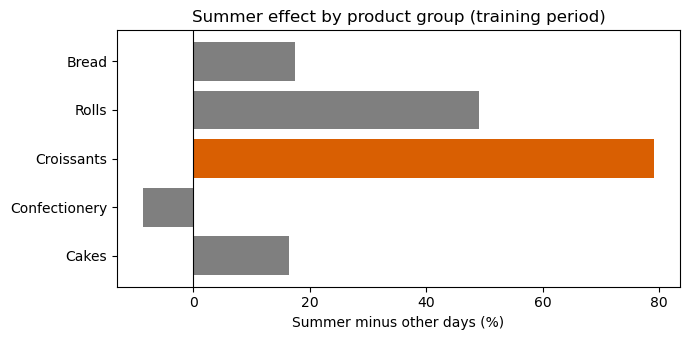

,summer mean,other mean,difference (EUR),difference (%),CI low,CI high
group,,,,,,
Bread,136.0,115.7,20.2,17.5,15.8,24.6
Rolls,539.8,362.3,177.5,49.0,163.2,191.9
Croissants,242.0,135.1,106.9,79.1,98.9,115.0
Confectionery,82.4,90.3,-7.9,-8.7,-11.4,-4.3
Cakes,313.0,268.6,44.3,16.5,35.3,53.4


In [6]:
names = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes"}
rows = []
for gid, name in names.items():
    g = train[train["Warengruppe"] == gid]
    a, b = g.loc[g["summer"], "Umsatz"], g.loc[~g["summer"], "Umsatz"]
    d = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
    rows.append({"group": name, "summer mean": a.mean(), "other mean": b.mean(),
                 "difference (EUR)": d, "difference (%)": d / b.mean() * 100,
                 "CI low": d - 1.96*se, "CI high": d + 1.96*se})
groups = pd.DataFrame(rows).set_index("group")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(groups.index[::-1], groups["difference (%)"][::-1],
        color=["#d95f02" if n == "Croissants" else "#7f7f7f" for n in groups.index[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Summer minus other days (%)")
ax.set_title("Summer effect by product group (training period)")
plt.tight_layout(); plt.show()
groups.round(1)

## Result

**The hypothesis is supported: in summer the bakery earns clearly more with croissants.**

- Average daily croissant revenue: 242.0 EUR in summer, 135.1 EUR on other days. Difference +106.9 EUR (+79 %), 95 % CI 98.9 to 115.0 EUR. The interval lies entirely above zero.
- The result barely changes when weekday (+106.9 EUR) or weekday and year (+106.0 EUR) are held fixed. The weekday mix is therefore not the reason.
- The effect appears in every year (+94 to +146 EUR). It was largest in 2013, which has only July and August as summer months.
- The months show a peak in July (252.7 EUR) and August (289.5 EUR). June (180.6 EUR) is only a little above spring and autumn (April 149.0, May 155.5, September 165.3, October 173.0). The summer effect is therefore concentrated in July and August, not spread evenly over the three months.
- Summer is not specific to croissants: rolls (+49 %), bread (+17.5 %) and cakes (+16.5 %) also rise, confectionery falls (-8.7 %). The croissant effect is the largest in relative terms.

**What this means for the prediction:** a seasonal signal (month as a feature, as already planned in D6) is worthwhile, and it should be allowed to differ by product group. A single "summer" flag would treat June like July and August, so month is the better choice.

**Limits:** revenue, not units; we do not know whether prices or opening hours changed. Only four to five summers are available. Weather (e.g. temperature) is not examined here, so we cannot say whether the season itself or the warm weather causes the effect.